# Explicit Faber-Jackson Luminosity-Dispersion Relationship
Just looking at the L-sigma relationship for Morphology 0, 0.5
Expecting log10(L) = 4*log10(sigma).

We'll use the absolute r-band Magnitude 'm_r' as a proxy for Luminosity.
We'll use the velocity dispersion at r_e, 'sigma_re'.

Same starting code as Fundamental_plane file.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import astropy.cosmology.units as cu
from astropy import units as u
from astropy.cosmology import FlatLambdaCDM

from scipy import stats
from scipy.optimize import curve_fit

In [2]:
samimorph = pd.read_csv('SAMI_Visual_Morphology/samiDR3VisualMorphology.csv')
samicat = pd.read_csv('SAMI_Input_Cat_Cluster/samiDR3InputCatClusters.csv')
samikin = pd.read_csv('SAMI_Kinematics/samiDR3StelKin.csv')

print('Sample Size of SAMI Visual Morphology Dataset:', len(samimorph))
print('Sample Size of SAMI Input Catalogue Dataset:', len(samicat))
print('Sample Size of SAMI Stellar Kinematics Dataset:', len(samikin))

morphcat = pd.merge(samimorph, samicat, on='catid', how='inner')
df = pd.merge(morphcat, samikin, on='catid', how='inner')
print('Final Data Set', len(df))
print(df.head(20))

Sample Size of SAMI Visual Morphology Dataset: 3068
Sample Size of SAMI Input Catalogue Dataset: 1433
Sample Size of SAMI Stellar Kinematics Dataset: 3426
Final Data Set 962
    Unnamed: 0_x       catid  type  Unnamed: 0_y     ra_obj   dec_obj  \
0           2151  9008500001   0.0           849  10.460211 -9.303184   
1           2152  9008500002   0.0           850  10.460158 -9.303645   
2           2153  9008500004   1.5           851  10.456779 -9.295304   
3           2154  9008500007   0.0           852  10.450953 -9.284216   
4           2154  9008500007   0.0           852  10.450953 -9.284216   
5           2155  9008500018   0.5           853  10.489803 -9.281996   
6           2156  9008500020   0.0           854  10.422118 -9.315872   
7           2157  9008500022   0.5           855  10.436680 -9.338163   
8           2158  9008500024   0.5           856  10.417239 -9.304267   
9           2159  9008500034   1.0           857  10.470191 -9.358393   
10          2160  90085

In [3]:
elliptical0 = df[df['type'] == 0.0] # choosing only elliptical galaxies
# key defines elliptical galaxies as having the type = 0
    # 0.5 is for galaxies between elliptical and lenticular stages

print('Number of Elliptical Galaxies:', len(elliptical0))

# Explicit Faber-Jackson needs m_r, sigma_re
rawdf0 = elliptical0[['catid', 'm_r', 'sigma_re', 'lambdar_re']]
print('Uncleaned Data Set:', len(rawdf0))
print(rawdf0.head(20))
    # mu_1re is in magnitude/arcsec^2, sigma_re is in km/s, r_e is in arcsec
    # we're going to have unit problems as effective radius needs to be in kpc

Number of Elliptical Galaxies: 152
Uncleaned Data Set: 152
         catid        m_r    sigma_re  lambdar_re
0   9008500001 -23.762243         NaN    0.155672
1   9008500002 -23.762140         NaN         NaN
3   9008500007 -21.877182  265.057370    0.250750
4   9008500007 -21.877182         NaN         NaN
6   9008500020 -21.548409  170.477860    0.120466
10  9008500042 -20.736303  202.322860    0.184598
12  9008500059 -21.090816  204.846340    0.077209
14  9008500064 -19.801918  125.197975         NaN
16  9008500068 -20.089985   87.443590    0.185957
20  9008500077 -21.459278  183.164600    0.214422
27  9008500096 -21.923738  164.250000    0.063525
34  9008500114 -22.267447         NaN    0.191316
36  9008500118 -20.496445  122.640700    0.196150
44  9008500138 -20.616693  114.042900         NaN
45  9008500139 -20.837872  131.962300    0.142941
47  9008500145 -20.579838         NaN    0.537963
52  9008500169 -21.435072  173.848070    0.125381
57  9008500182 -20.753191  166.522140    

In [4]:
elliptical05 = df[df['type'] == 0.5] # choosing only elliptical galaxies
# key defines elliptical galaxies as having the type = 0
    # 0.5 is for galaxies between elliptical and lenticular stages

print('Number of Elliptical Galaxies:', len(elliptical05))

# fundamental plane needs effective radius, velocity dispersion and effective brightness
rawdf05 = elliptical05[['catid', 'm_r', 'sigma_re', 'lambdar_re']]
print('Uncleaned Data Set:', len(rawdf05))
print(rawdf05.head(20))
    # mu_1re is in magnitude/arcsec^2, sigma_re is in km/s, r_e is in arcsec
    # we're going to have unit problems as effective radius needs to be in kpc


Number of Elliptical Galaxies: 128
Uncleaned Data Set: 128
          catid        m_r    sigma_re  lambdar_re
5    9008500018 -19.757118  130.505040         NaN
7    9008500022 -20.102259   98.179590    0.099933
8    9008500024 -21.341162  187.108870    0.154685
38   9008500122 -20.363594  129.695770    0.217057
40   9008500130 -20.691612         NaN         NaN
41   9008500134 -20.103214  151.563870         NaN
42   9008500135 -22.451832         NaN         NaN
49   9008500160 -20.003430   94.033200    0.301095
60   9008500193 -19.694584  121.194030         NaN
62   9008500197 -20.119460  113.182630    0.228826
65   9008500208 -20.761435         NaN         NaN
79   9008500240 -20.108534  107.679016    0.293863
80   9008500245 -21.682932  259.273900    0.294901
82   9008500249 -20.349035  117.748024    0.250181
101  9008500339 -20.519500  102.274740    0.166410
103  9008500351 -20.861794  139.870180    0.165303
105  9008500359 -20.340437  151.968610    0.175718
124  9008500533 -19.801

# Cleaning Data Sets (NaN's and Uniqueness)
Following Fundamental_Plane method, but filtering NaNs only in Luminosity and Dispersion.

We get 107/96 (Morphology 0/0.5) without filtering by lambdar_re NaNs, and now we have 87/79.

In [12]:
df_clean_elliptical0 = rawdf0.dropna(subset = ['m_r', 'sigma_re', 'lambdar_re'])
print('Cleaned Data Set', len(df_clean_elliptical0))
RemovedSamples0 = len(rawdf0) - len(df_clean_elliptical0)
print('Number of Samples Removed:', RemovedSamples0)

df_clean_elliptical05 = rawdf05.dropna(subset = ['m_r', 'sigma_re', 'lambdar_re'])
print('Cleaned Data Set', len(df_clean_elliptical05))
RemovedSamples05 = len(rawdf05) - len(df_clean_elliptical05)
print('Number of Samples Removed:', RemovedSamples05)

# Reusing code from Conservative_Elliptical_Raw to check each catid is unique
# And that all dispersion values are positive as we are taking logarithm later
uniquecatids = df_clean_elliptical0['catid'].nunique()
print('Number of unique catid values in elliptical Dataframe:', uniquecatids)
print("Does unique catid values = total number of rows in elliptical0 dataframe?", uniquecatids == len(df_clean_elliptical0))

uniquecatids = df_clean_elliptical05['catid'].nunique()
print('Number of unique catid values in elliptical Dataframe:', uniquecatids)
print("Does unique catid values = total number of rows in elliptical05 dataframe?", uniquecatids == len(df_clean_elliptical05))



if df_clean_elliptical0['sigma_re'].min() > 0:
    print("There are no negative values (or zero) in the sigma_re column, good to go :)")
else: 
    print("There are negative values in the sigma_re column for morphology 0, filter before taking logarithm")

if df_clean_elliptical05['sigma_re'].min() > 0:
    print("There are no negative values (or zero) in the sigma_re column, good to go :)")
else: 
    print("There are negative values in the sigma_re column for morphology 0.5, filter before taking logarithm")

Cleaned Data Set 87
Number of Samples Removed: 65
Cleaned Data Set 79
Number of Samples Removed: 49
Number of unique catid values in elliptical Dataframe: 87
Does unique catid values = total number of rows in elliptical0 dataframe? True
Number of unique catid values in elliptical Dataframe: 79
Does unique catid values = total number of rows in elliptical05 dataframe? True
There are no negative values (or zero) in the sigma_re column, good to go :)
There are no negative values (or zero) in the sigma_re column, good to go :)


# Plotting Luminosity against Dispersion
Going to plot logged values.

To convince everyone that Absolute Magnitude relates to Luminosity correctly (**need help with the explaining**), note that 

M - M_sun = -2.5\*log10(F/F_sun).

So F/F_sun = 10\*\*((M-M_sun)/-2.5).

and F = F_sun \* 10^((M-M_sun)/-2.5). This is expected to be proportional to sigma^4.

and log10(F) = log10(F_sun \* 10^(-M/2.5) \* 10^(M_sun/2.5)).

But this is log10(F) = M/-2.5 + additive constants! Hence, we will neglect to put in F_sun and M_sun as they do not affect the gradient of the log-log plot.

Lastly, F = L/(4\*π\*d^2), where d = 10 pc is standardised, so F is a proxy for L.

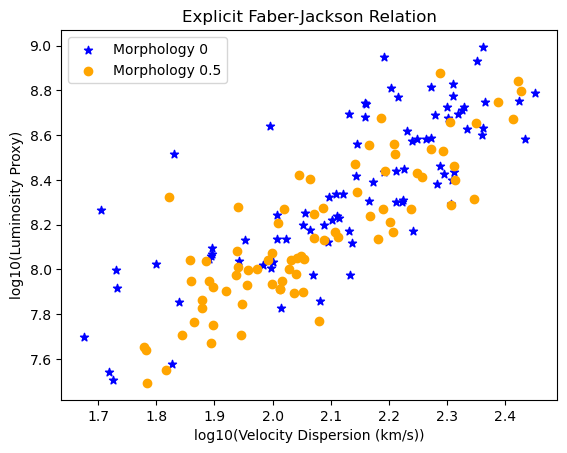

In [13]:
M0 = df_clean_elliptical0['m_r'];
F0 = 10**(M0/-2.5); # un-logging and converting to Luminosity, a direct proxy
M05 = df_clean_elliptical05['m_r'];
F05 = 10**(M05/-2.5); # un-logging.

sigma0 = df_clean_elliptical0['sigma_re'];
sigma05 = df_clean_elliptical05['sigma_re'];


plt.scatter(np.log10(sigma0), np.log10(F0), marker='*', color='blue', label='Morphology 0')
plt.scatter(np.log10(sigma05), np.log10(F05), marker='o', color='orange', label='Morphology 0.5')
plt.xlabel('log10(Velocity Dispersion (km/s))')
plt.ylabel('log10(Luminosity Proxy)')
plt.title("Explicit Faber-Jackson Relation")
plt.legend();

plt.show()

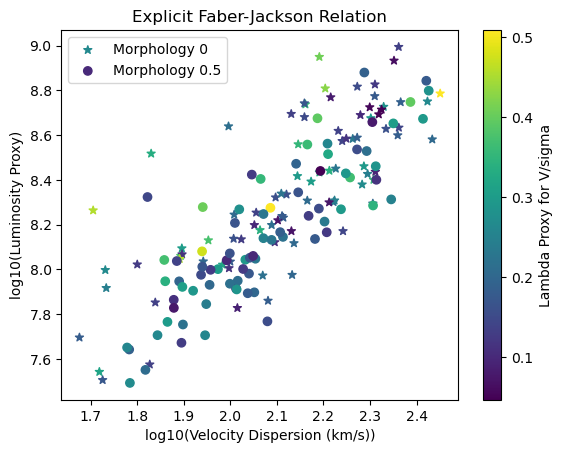

In [18]:
## This is a check to see if the elliptical galaxies (as per Visual Morphology) are actually slow-rotators
## using lambdar_re. As a reminder, lambdar_re < 0.1 is a good condition for a dispersion-supported galaxy.
## This corresponds to a very dark blue, which as we can see is not the majority on the graph.

lambdar_re0 = df_clean_elliptical0['lambdar_re'];
lambdar_re05 = df_clean_elliptical05['lambdar_re'];

plt.scatter(np.log10(sigma0), np.log10(F0), marker='*', c=lambdar_re0, label='Morphology 0')
plt.scatter(np.log10(sigma05), np.log10(F05), marker='o', c=lambdar_re05, label='Morphology 0.5')
plt.xlabel('log10(Velocity Dispersion (km/s))')
plt.ylabel('log10(Luminosity Proxy)')
plt.title("Explicit Faber-Jackson Relation")
cbar = plt.colorbar()
cbar.set_label('Lambda Proxy for V/sigma')
plt.legend();

# Statistical Analysis
To be done.

In [ ]:
# Using linear regression to find slope of F-J relation for 
# Morphology 0 and 0.5 galaxies
regress0 = stats.linregress(np.log10(sigma0), np.log10(F0))
regress05 = stats.linregress(np.log10(sigma05), np.log10(F05))
grad0 = regress0.slope
grad05 = regress05.slope
print("Slope of galaxies with morphology 0 (gamma) = ", grad0)
print("Slope of galaxies with morphology 0.5 (gamma) = ", grad05)

# Now lets find the standard error of the slope for both morphologies
stderr0 = regress0.stderr
stderr05 = regress05.stderr
print("Standard error of slope for galaxies with morphology 0: ", stderr0)
print("Standard error of slope for galaxies with morphology 0.5: ", stderr05)

# Also want the intercepts for the linear regression lines 
# For both morphologies
int0 = regress0.intercept
int05 = regress05.intercept
print("y intercept of galaxies with a morphology of 0: ", int0)
print("y intercept of galaxies with a morphology of 0.5: ", int05)


# Now we plot the linear regression lines for
# Both morphologies over existing scatter plot

plt.scatter(np.log10(sigma0), np.log10(F0), marker='*', color='blue', label='Morphology 0')
plt.scatter(np.log10(sigma05), np.log10(F05), marker='o', color='orange', label='Morphology 0.5')

# For plotting scatter we use np.linsapace to create evenly spaced 
# x values for linear regression lines that start at the minimum of log10(sigma0 and sigma05) respectively
# And end at the maximum of log10(sigma0 and sigma05)

x0 = np.linspace(np.log10(sigma0).min(), np.log10(sigma0).max(), 1000)
x05 = np.linspace(np.log10(sigma05).min(), np.log10(sigma05).max(), 1000)
plt.plot(x0, grad0 *x0 + int0, color = 'blue', label = 'Linear Regression Morphology 0')
plt.plot(x05,grad05 * x05 + int05, color = 'orange', label = 'Linear Regression Morphology 0.5')
plt.xlabel('log10(Velocity Dispersion (km/s))')
plt.ylabel('log10(Luminosity Proxy)')
plt.title("Explicit Faber-Jackson Relation")
plt.legend()
plt.show()

